<a href="https://colab.research.google.com/github/muhammadghazali-bit/ProgramDS/blob/main/Tugas_Visualisasi_Ghaza.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **VISUALISASI DATA FISKAL**


Sumber data
https://github.com/Alam-A99/DATAAKSI/blob/main/dataset_fiskal_97_hipoFull.csv
atau
https://drive.google.com/file/d/1IuMKzmdv7x7OUjuvNwC7rQ8r9oVUFpAI/view?usp=sharing

# **10 kota dengan rata-rata pengangguran tertinggi**

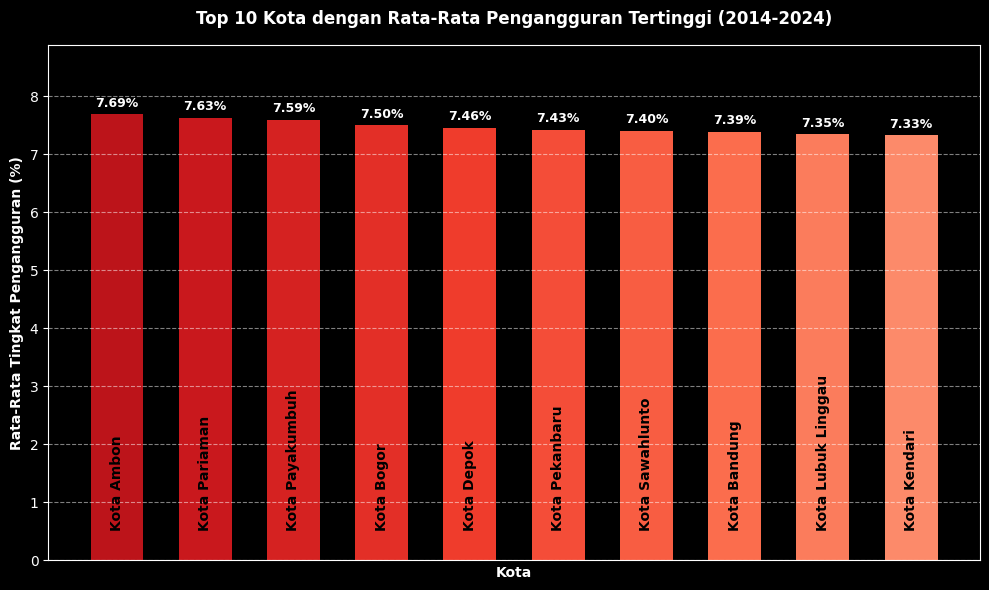

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# =================================================================
# Gunakan format URL "Raw" dari GitHub
url = 'https://raw.githubusercontent.com/Alam-A99/DATAAKSI/main/dataset_fiskal_97_hipoFull.csv'
data = pd.read_csv(url)

# 1. Hitung 10 kota dengan rata-rata pengangguran tertinggi
top10_kota_pengangguran = data.groupby("Kota")["PENGANGGURAN"].mean().nlargest(10)

# 2. Buat visualisasi grafik batang vertikal (berdiri)
colors = plt.cm.Reds(np.linspace(0.8, 0.4, len(top10_kota_pengangguran)))
plt.style.use('dark_background')
plt.figure(figsize=(10, 6))
bars = plt.bar(
    top10_kota_pengangguran.index,
    top10_kota_pengangguran.values,
    color=colors,
    width=0.6,
)

plt.title(
    "Top 10 Kota dengan Rata-Rata Pengangguran Tertinggi (2014-2024)",
    fontweight="bold",
    color="#ffffff",
    pad=15,
)

plt.ylabel(
    "Rata-Rata Tingkat Pengangguran (%)",
    fontweight="bold",
    color="#ffffff"
)
plt.xlabel(
    "Kota",
    fontweight="bold",
    color="#ffffff"
)

# plt.xticks(rotation=45, ha="right")  # Miringkan label kota 45 derajat
plt.xticks([])

# Menambahkan label persentase di atas setiap batang
for i, bar in enumerate(bars):
    yval = bar.get_height()
    city = top10_kota_pengangguran.index[i]

    # Label persentase di atas batang
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        yval + 0.08,
        f"{yval:.2f}%",
        ha="center",
        va="bottom",
        fontweight="bold",
        fontsize=9,
    )

    # Nama kota DI DALAM BATANG (posisi Y = 0.5 di dekat alas)
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        0.5,
        city,
        ha="center",
        va="bottom",
        rotation=90,
        color="black",
        fontweight="bold",
        fontsize=10,
    )

plt.ylim(0, max(top10_kota_pengangguran.values) + 1.2)
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

# **10 kota dengan rata-rata pengangguran terendah**

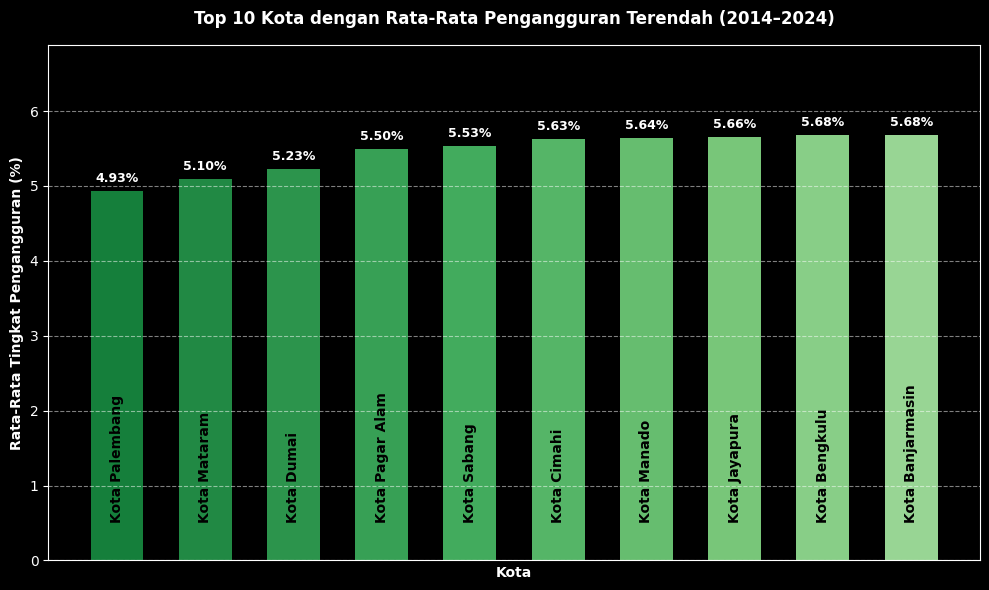

In [ ]:
# 1. Hitung 10 kota dengan rata-rata pengangguran terendah
top10_kota_pengangguran = data.groupby("Kota")["PENGANGGURAN"].mean().nsmallest(10)

# 2. Buat visualisasi grafik batang
colors = plt.cm.Greens(np.linspace(0.8, 0.4, len(top10_kota_pengangguran)))
plt.style.use('dark_background')
plt.figure(figsize=(10, 6))
bars = plt.bar(
    top10_kota_pengangguran.index,
    top10_kota_pengangguran.values,
    color= colors,
    width=0.6,
)

plt.title(
    "Top 10 Kota dengan Rata-Rata Pengangguran Terendah (2014–2024)",
    fontweight="bold",
    color= "#FFFFFF",
    pad=15,
)

plt.ylabel(
  "Rata-Rata Tingkat Pengangguran (%)",
  fontweight='bold',
  color= "#ffffff"
  )
plt.xlabel(
  "Kota",
  fontweight='bold',
  color= "#ffffff"
  )
# plt.xticks(rotation=45, ha="right")  # Miringkan label kota 45 derajat
plt.xticks ([])

# Menambahkan label persentase di atas setiap batang
for i, bar in enumerate(bars):
  yval = bar.get_height()
  city = top10_kota_pengangguran.index[i]
  plt.text(
      bar.get_x() + bar.get_width() / 2,
      yval + 0.08,
      f"{yval:.2f}%",
      ha="center",
      va="bottom",
      fontweight="bold",
      fontsize=9,
  )

# Nama kota DI DALAM BATANG (posisi Y = 0.5 di dekat alas)
  plt.text(
      bar.get_x() + bar.get_width() / 2,
      0.5,
      city,
      ha="center",
      va="bottom",
      rotation=90,
      color="black",
      fontweight="bold",
      fontsize=10,
  )

plt.ylim(0, max(top10_kota_pengangguran.values) + 1.2)
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()


# **Tren Komposisi Pendapatan Rata-Rata Kota**

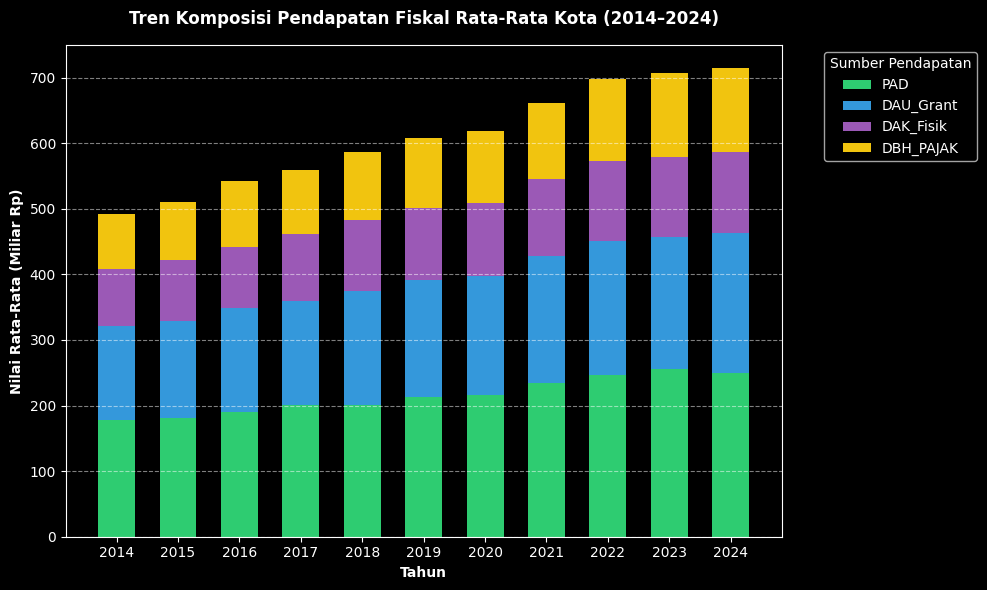

In [ ]:
# Stacked Bar Chart (Komposisi Pendapatan Fiskal Daerah)

data_fiskal = data.groupby("Tahun")[
    ["PAD", "DAU_Grant", "DAK_Fisik", "DBH_PAJAK"]
].mean()

plt.figure(figsize=(10, 6))
bottom = np.zeros(len(data_fiskal))
colors = ["#2ecc71", "#3498db", "#9b59b6", "#f1c40f"]

# Ubah index Tahun menjadi string
x_years = data_fiskal.index.astype(str)

for col, color in zip(data_fiskal.columns, colors):
  plt.bar(
      x_years, data_fiskal[col], bottom=bottom, label=col, color=color, width=0.6
  )
  bottom += data_fiskal[col]

plt.title(
    "Tren Komposisi Pendapatan Fiskal Rata-Rata Kota (2014–2024)",
    fontweight="bold",
    pad=15,
)

plt.xlabel(
  "Tahun",
  fontweight= 'bold'
)

plt.ylabel(
  "Nilai Rata-Rata (Miliar Rp)",
  fontweight='bold'
)
plt.legend(title="Sumber Pendapatan", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()


# **Perbandingan Tren Kemiskinan Antar Kota**

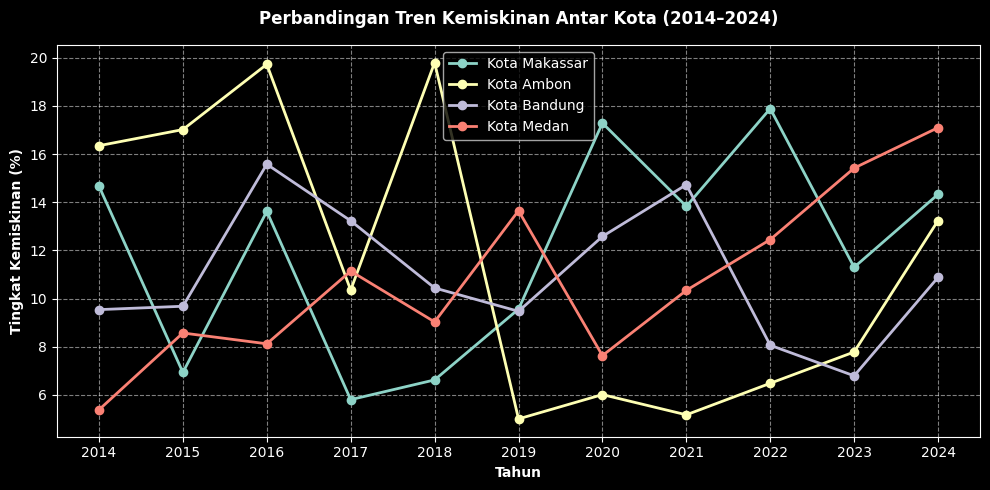

In [ ]:
# Line Chart Perbandingan Tren Antar Kota Spesifik#
data["Tahun"] = data["Tahun"].astype(str)  # <-- TAMBAHKAN BARIS INI

# Filter beberapa kota yang ingin dibandingkan
kota_pilihan = ["Kota Makassar", "Kota Ambon", "Kota Bandung", "Kota Medan"]
df_filtered = data[data["Kota"].isin(kota_pilihan)]

plt.figure(figsize=(10, 5))
for kota in kota_pilihan:
  data_kota = df_filtered[df_filtered["Kota"] == kota]
  plt.plot(
      data_kota["Tahun"],
      data_kota["KEMISKINAN"],
      marker="o",
      linewidth=2,
      label=kota,
  )

plt.title(
    "Perbandingan Tren Kemiskinan Antar Kota (2014–2024)",
    fontweight="bold",
    pad=15,
)

plt.xlabel(
  "Tahun",
  fontweight= 'bold'
)

plt.ylabel(
  "Tingkat Kemiskinan (%)",
  fontweight='bold'
)
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()